In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = "data/dataset.h5ad"

adata = sc.read_h5ad(data_path)

In [2]:
# Normalizing to median total counts
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

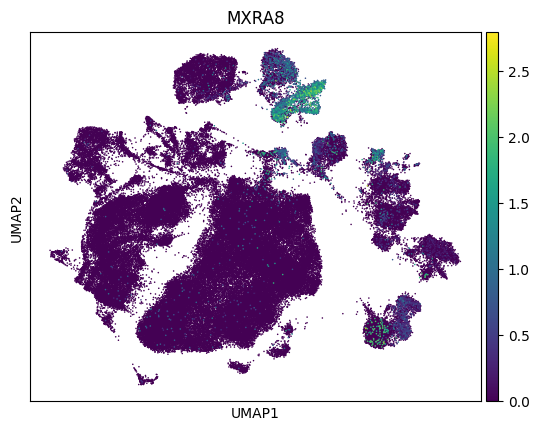

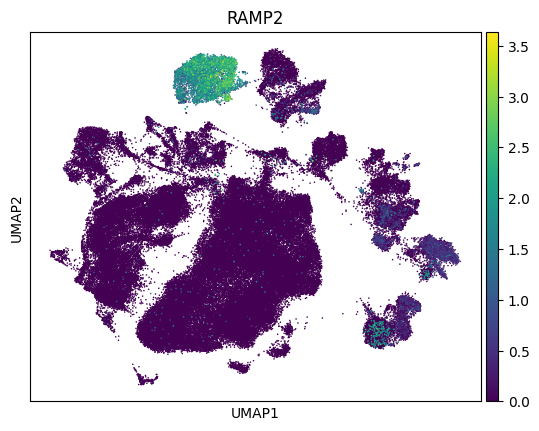

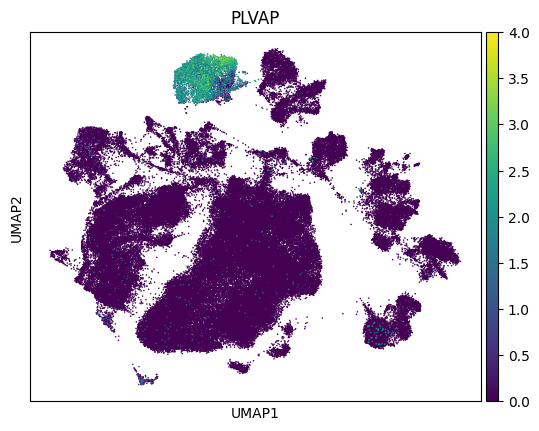

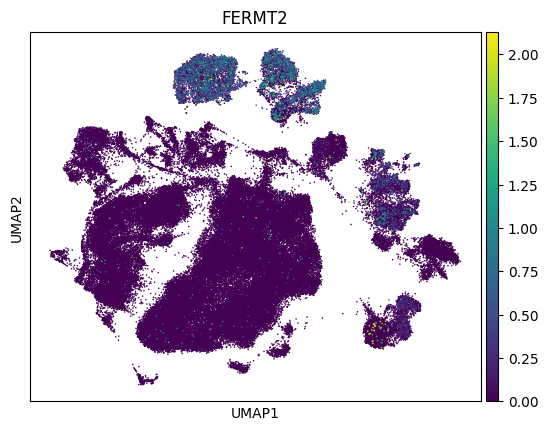

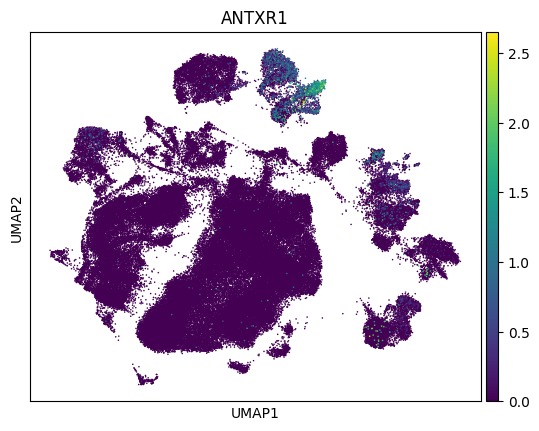

In [3]:
my_targets = ['MXRA8', 'RAMP2', 'PLVAP', 'FERMT2', 'ANTXR1']
for target in my_targets:
    sc.pl.umap(
        adata,
        color=target,
        legend_loc="on data",
        size=5
    )

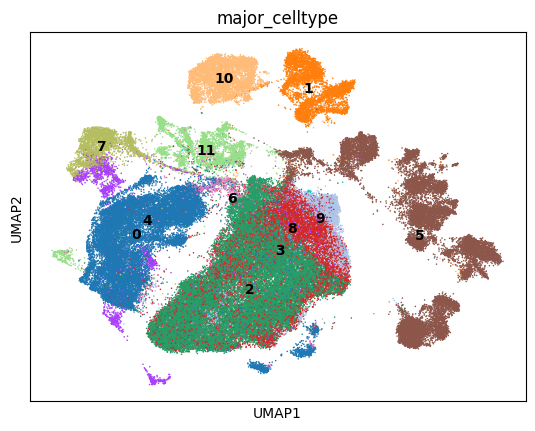

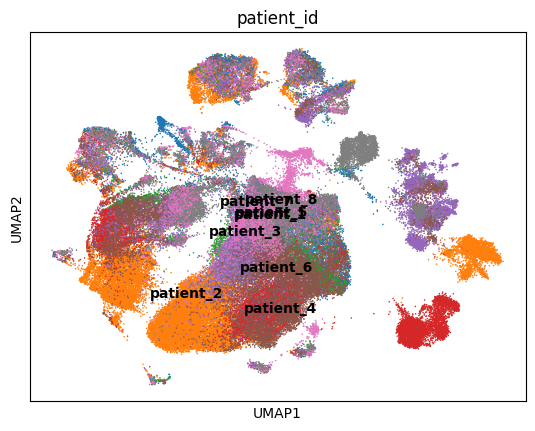

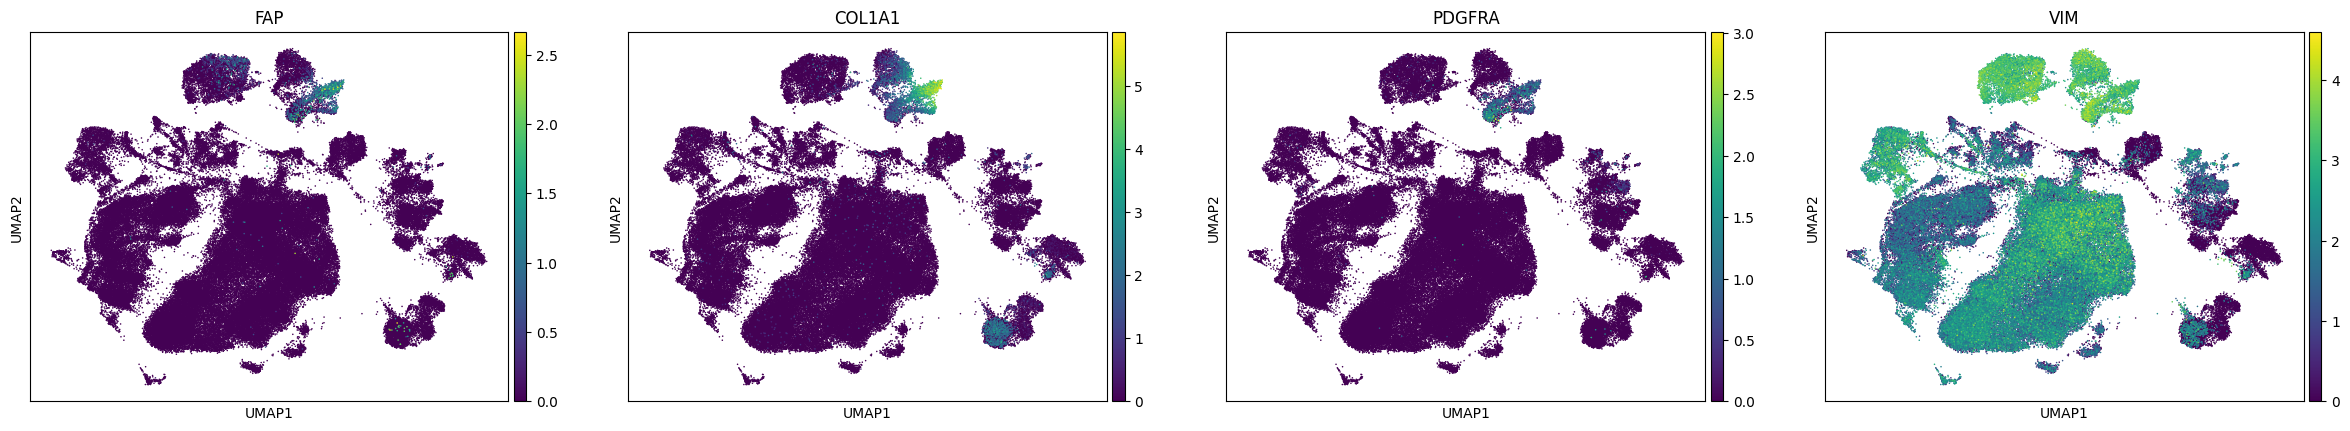

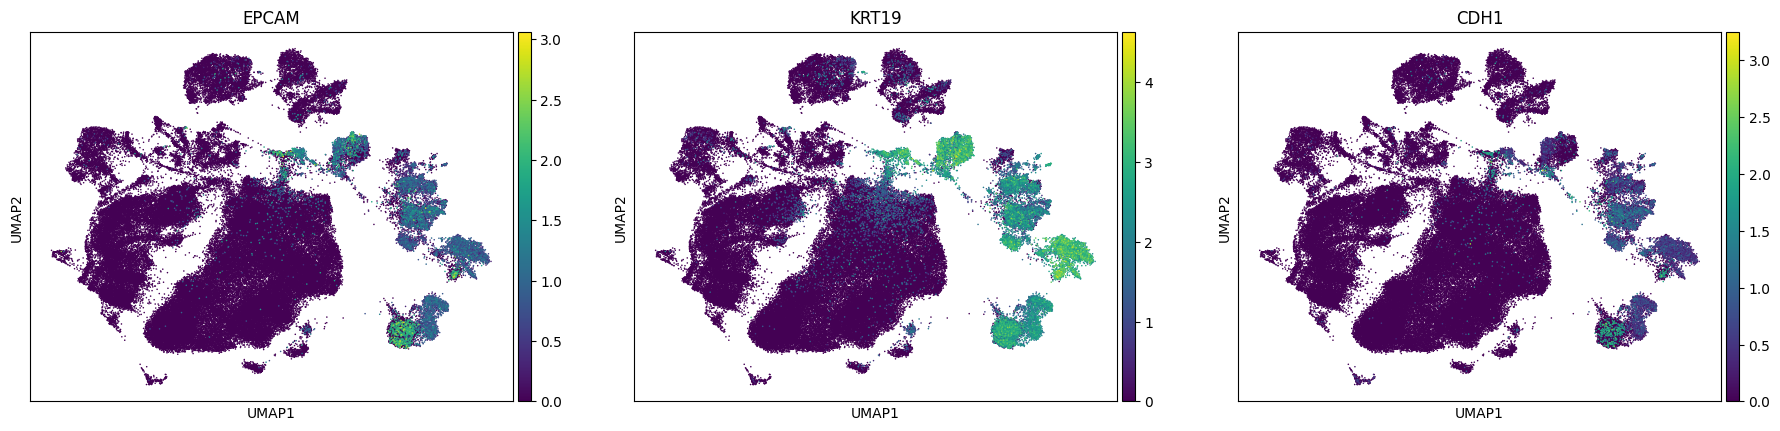

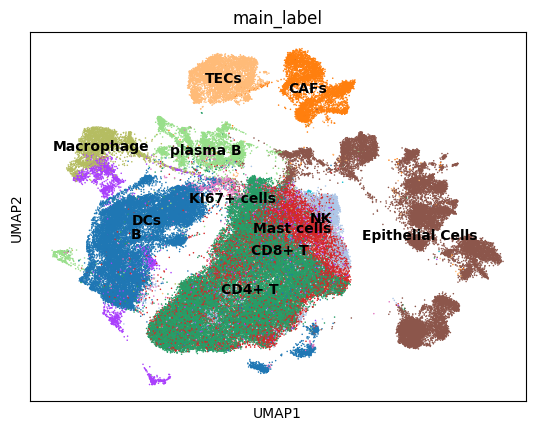

In [ ]:
adata.obs["major_celltype"] = adata.obs["major_celltype"].astype(str)
sc.pl.umap(
    adata,
    color="major_celltype",
    legend_loc="on data",
    size=5
)
sc.pl.umap(
    adata,
    color="patient_id",
    legend_loc="on data",
    size=5
)

stromal_markers = ['FAP', 'COL1A1', 'PDGFRA', 'VIM']
epithelial_markers = ['EPCAM', 'KRT19', 'CDH1']
sc.pl.umap(
    adata,
    color=stromal_markers,
    legend_loc="on data",
    size=5
)
sc.pl.umap(
    adata,
    color=epithelial_markers,
    legend_loc="on data",
    size=5
)

sc.pl.umap(
    adata,
    color="main_label",
    legend_loc="on data",
    size=5
)

categories: 0, 1, 2, etc.
var_group_labels: Stromal, Epithelial


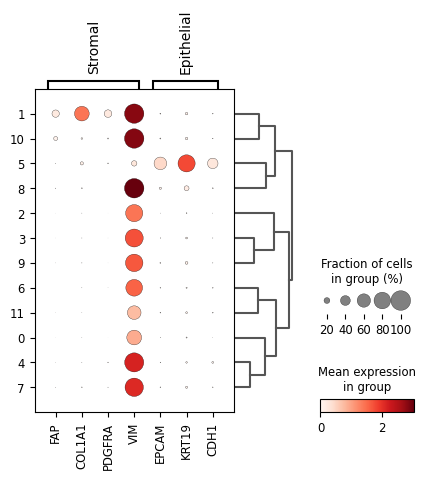

In [33]:
marker_genes_dict = {"Stromal": stromal_markers, "Epithelial": epithelial_markers}
adata.obs["major_celltype"] = adata.obs["major_celltype"].astype(str)
sc.pl.dotplot(adata, marker_genes_dict, "major_celltype", dendrogram=True)

<Axes: title={'center': 'main_label'}, xlabel='UMAP1', ylabel='UMAP2'>

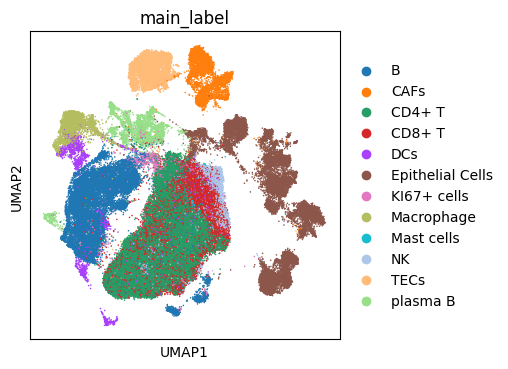

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(
    adata,
    ax=ax,
    show=False,
    color="main_label",
    size=5
)